In [31]:
from matplotlib import pyplot as plt  # data visualization
import numpy as np                    # numerical computations
import pandas as pd                   # dataframes

In [32]:
energy_2023_clean = pd.read_csv("https://raw.github.com/Alissa-Ouspen/data110_alissa/main/datasets/energy_2023_clean.csv")
energy_2023_clean.head()

,Benchmarking Group,ESPM Property ID,Building Name,Montgomery County Building ID,Reporting Year Start Date,Benchmarking Report Status,Address,City,State,Zip,...,Electricity Use Onsite Renewable (kWh),Natural Gas (therms),Site EUI,Weather-Normalized Site EUI,Source EUI,Weather-Normalized Source EUI,Total GHG Emissions (Metric Tons CO2e),GHG Emissions Intensity (kgCO2e/ft²),Direct GHG Emissions (Metric Tons CO2e),Direct GHG Emissions Intensity (kgCO2e/ft²)
0,County,5244852.0,council office building***,00152444,2016,in compliance,100 maryland ave,rockville,maryland,20850,...,"36,193.6","16,129.2",111.7,114.5,289.4,292.4,"1,219",NaN,85.7,0.7
1,County,5245108.0,grey courthouse*,00152455,2016,in compliance,27 courthouse sq,rockville,maryland,20850,...,0,"11,846.2",50.9,55.0,120.1,124.4,372,NaN,62.9,0.7
2,County,5244851.0,white oak crcc,00278286,2015,in compliance,1700 april ln,silver spring,maryland,20904,...,0,"1,086.9",47.0,47.0,128,128,218.9,NaN,5.8,0.1
3,County,5245118.0,dennis ave health center***,00954308,2015,in compliance,2000 dennis ave,silver spring,maryland,20902,...,0,"38,170.8",122.7,125.8,218.5,219.8,443.1,NaN,202.7,3.8
4,County,20658934.0,wheaton library/ recreation centerc,01093362,2015,in compliance,11701 georgia ave,silver spring,maryland,20902,...,0,"32,603.7",91.9,96.6,180.3,184.1,484.2,NaN,173.2,2.3


In [34]:
# show all the unique categories in "Primary Property Type EPA Calculated"
# and the number of entries in each category

category_counts = energy_2023_clean["Primary Property Type EPA Calculated"].value_counts(dropna = False)
display(category_counts)

,count
Primary Property Type EPA Calculated,
multifamily housing,545
office,415
worship facility,79
NaN,70
k-12 school,54
self-storage facility,54
medical office,52
hotel,50
supermarket/grocery store,47


In [35]:
# group all categories with < 50 entries into "other"

# identify categories with less than 50 entries
rare_categories = category_counts[category_counts < 50].index

# copy df under new name
energy_2023_format1 = energy_2023_clean.copy()

# replace those categories with "other"
energy_2023_format1["Primary Property Type EPA Calculated"] = energy_2023_format1["Primary Property Type EPA Calculated"].replace(rare_categories, "other")

# display new value counts
energy_2023_format1["Primary Property Type EPA Calculated"].value_counts(dropna = False)

,count
Primary Property Type EPA Calculated,
multifamily housing,545
other,502
office,415
worship facility,79
NaN,70
k-12 school,54
self-storage facility,54
medical office,52
hotel,50


In [36]:
import matplotlib.colors as mcolors

# Get the "tab10" colormap object
tab10_cmap = plt.get_cmap("tab10")

# Access the list of colors from the colormap and convert to hex codes
hex_color_codes = [mcolors.to_hex(color) for color in tab10_cmap.colors]

# Display the hex color codes
print("Hex color codes for \"tab10\" colormap:")
for i, hex_code in enumerate(hex_color_codes):
    print(f'"{hex_code}"')

Hex color codes for "tab10" colormap:
"#1f77b4"
"#ff7f0e"
"#2ca02c"
"#d62728"
"#9467bd"
"#8c564b"
"#e377c2"
"#7f7f7f"
"#bcbd22"
"#17becf"


In [37]:
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b","#e377c2", "#7f7f7f"]

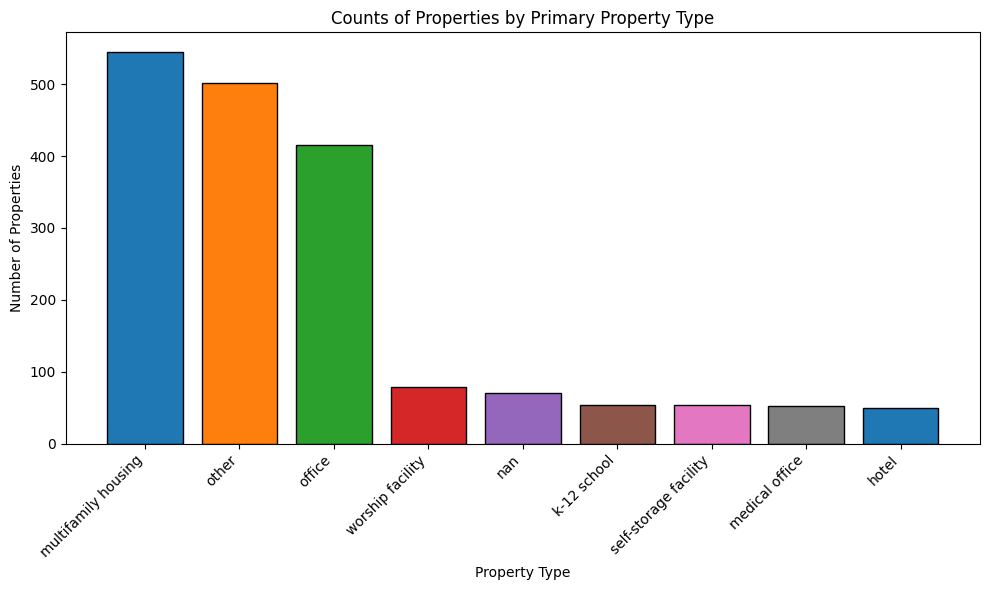

In [38]:
# Get the counts for each formatted category
formatted_counts = energy_2023_format1["Primary Property Type EPA Calculated"].value_counts(dropna = False)

# Plot the bar chart (histogram of category frequencies)
plt.figure(figsize = (10, 6))
plt.bar(formatted_counts.index.astype(str), formatted_counts.values, color = colors, edgecolor = "black")
plt.title("Counts of Properties by Primary Property Type")
plt.xlabel("Property Type")
plt.ylabel("Number of Properties")
plt.xticks(rotation = 45, ha = "right")
plt.tight_layout()
plt.show()

In [77]:
# target property types
target_properties = ["multifamily housing", "office", "worship facility", "k-12 school"]

# filter the dataframe
filtered_df = energy_2023_format1[
    energy_2023_format1["Primary Property Type EPA Calculated"].isin(target_properties)].copy()

# find relevant electricity usage column in your dataset
elec_col = [col for col in filtered_df.columns if "Electricity" in col and "Grid" in col]
if not elec_col:
    elec_col = [col for col in filtered_df.columns if "Electricity" in col]

electricity_column = elec_col[0] if elec_col else "Electricity Use Onsite Renewable (kWh)"
ghg_column = "Total GHG Emissions (Metric Tons CO2e)"

# clean columns and cast to numeric (handling commas and potential strings)
for col in [electricity_column, ghg_column]:
    filtered_df[col] = filtered_df[col].astype(str).str.replace(",", "", regex = True)
    filtered_df[col] = pd.to_numeric(filtered_df[col], errors = "coerce")

colors_sub = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

# default sizes 10, 12, 14
fs_title = 16
fs_label = 14
fs_ticks = 12


### Graph 1: Distribution of Electricity Usage by Property Type

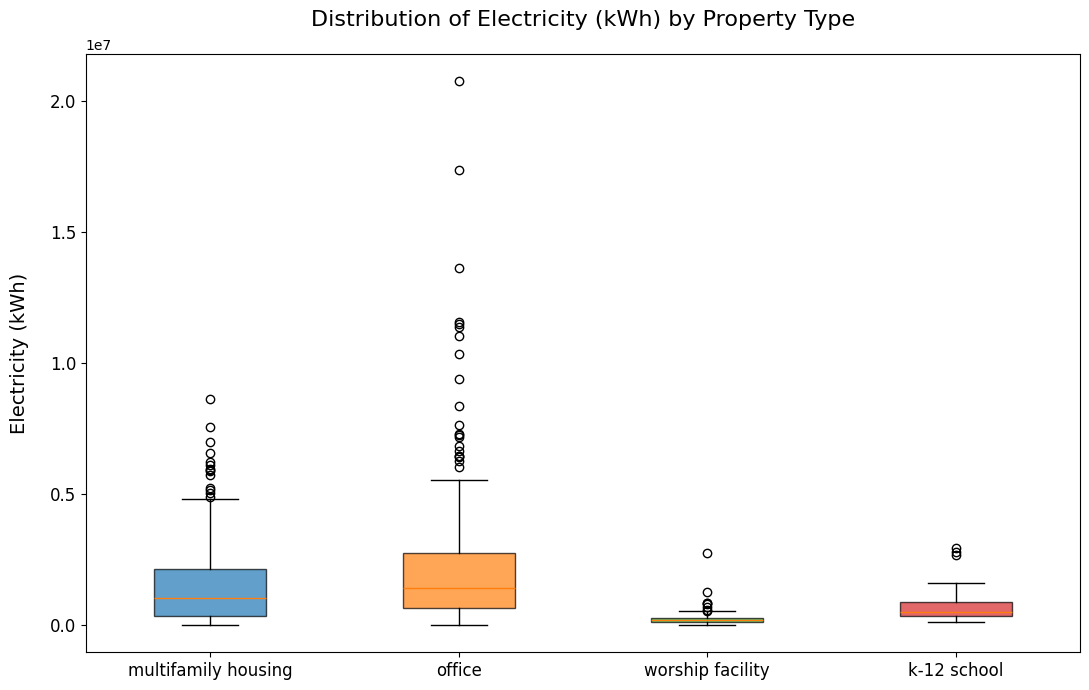

In [40]:
plt.figure(figsize = (11, 7))
bp1 = plt.boxplot(
    [filtered_df[filtered_df[
        "Primary Property Type EPA Calculated"] == prop][
            electricity_column].dropna() for prop in target_properties],
    tick_labels = target_properties,
    patch_artist = True
)

for patch, color in zip(bp1['boxes'], colors_sub):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

plt.title(
    f"Distribution of {electricity_column} by Property Type",
    pad=20, fontsize=fs_title)
plt.ylabel(electricity_column, labelpad = 15, fontsize = fs_label)
plt.xticks(rotation = 0, fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.tight_layout()
plt.show()

### Graph 2: Distribution of Total GHG Emissions by Property Type

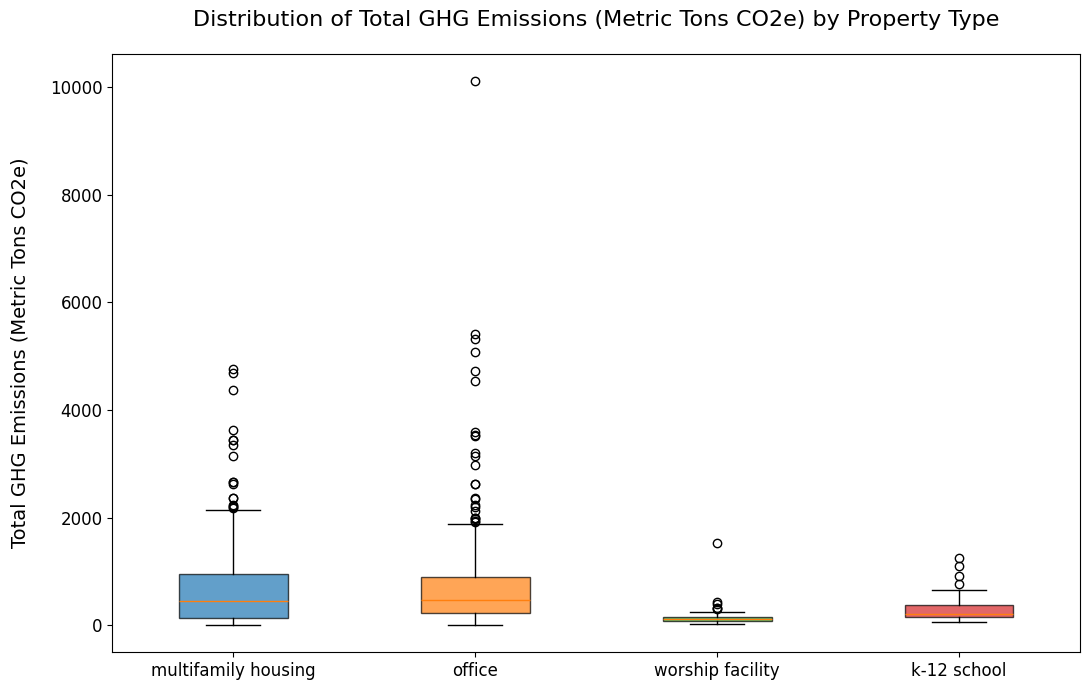

In [78]:
plt.figure(figsize = (11, 7))
bp2 = plt.boxplot(
    [filtered_df[filtered_df[
        "Primary Property Type EPA Calculated"] == prop][
            ghg_column].dropna() for prop in target_properties],
    tick_labels = target_properties,
    patch_artist = True
)

# Color the boxes
for patch, color in zip(bp2['boxes'], colors_sub):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

plt.title(
    f"Distribution of {ghg_column} by Property Type", pad = 20, fontsize = fs_title)
plt.ylabel(ghg_column, labelpad = 15, fontsize = fs_label)
plt.xticks(rotation = 0, fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.tight_layout()
plt.show()

### Graph 3: Violin Plot of Electricity Usage by Property Type

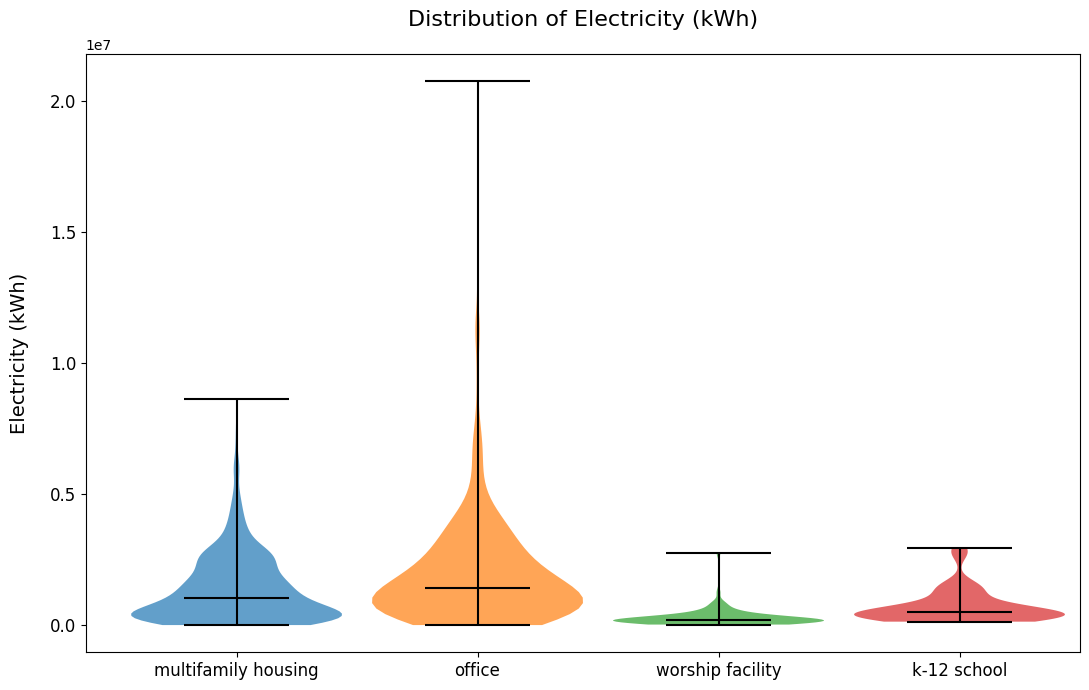

In [59]:
plt.figure(figsize = (11, 7))

# Prepare data list for violin plot
data_elec = [filtered_df[filtered_df[
    "Primary Property Type EPA Calculated"] == prop][
        electricity_column].dropna() for prop in target_properties]

# Positions packed closer
new_positions = [.9, 1.7, 2.5, 3.3]

vp5 = plt.violinplot(
    data_elec, positions = new_positions, showmeans = False,
    showmedians = True, showextrema = True, widths = 0.70)

# Color the violins
for patch, color in zip(vp5["bodies"], colors_sub):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Customize colors of line elements
vp5["cmedians"].set_color("black")
vp5["cmins"].set_color("black")
vp5["cmaxes"].set_color("black")
vp5["cbars"].set_color("black")

plt.title(f"Distribution of {electricity_column}", pad = 20, fontsize = fs_title)
plt.ylabel(electricity_column, labelpad = 15, fontsize = fs_label)
# Set custom ticks to align with the new packed positions
plt.xticks(
    ticks = new_positions, labels = target_properties,
    rotation = 0, fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.xlim(0.4, 3.7)
plt.tight_layout()
plt.show()

### Graph 4: Violin Plot of Total GHG Emissions by Property Type

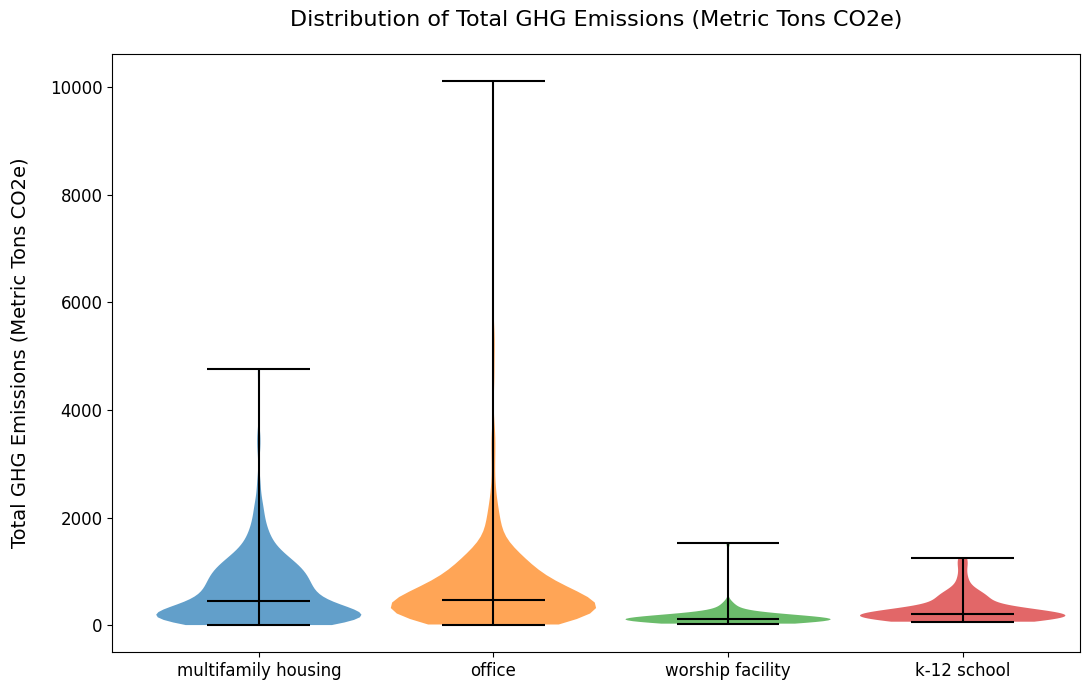

In [60]:
plt.figure(figsize = (11, 7))

# Prepare data list for violin plot
data_ghg = [filtered_df[filtered_df["Primary Property Type EPA Calculated"] == prop][ghg_column].dropna() for prop in target_properties]

new_positions = [.9, 1.7, 2.5, 3.3]

vp6 = plt.violinplot(
    data_ghg, positions = new_positions, showmeans = False,
    showmedians = True, showextrema = True, widths = 0.70)

for patch, color in zip(vp6["bodies"], colors_sub):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)


vp6["cmedians"].set_color("black")
vp6["cmins"].set_color("black")
vp6["cmaxes"].set_color("black")
vp6["cbars"].set_color("black")

plt.title(f"Distribution of {ghg_column}", pad = 20, fontsize = fs_title)
plt.ylabel(ghg_column, labelpad = 15, fontsize = fs_label)
# Set custom ticks to align with the new packed positions
plt.xticks(
    ticks = new_positions, labels = target_properties,
    rotation = 0, fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.xlim(0.4, 3.7)
plt.tight_layout()
plt.show()

### Graph 5: Scatterplot Comparing Gross Floor Area to Electricity Use

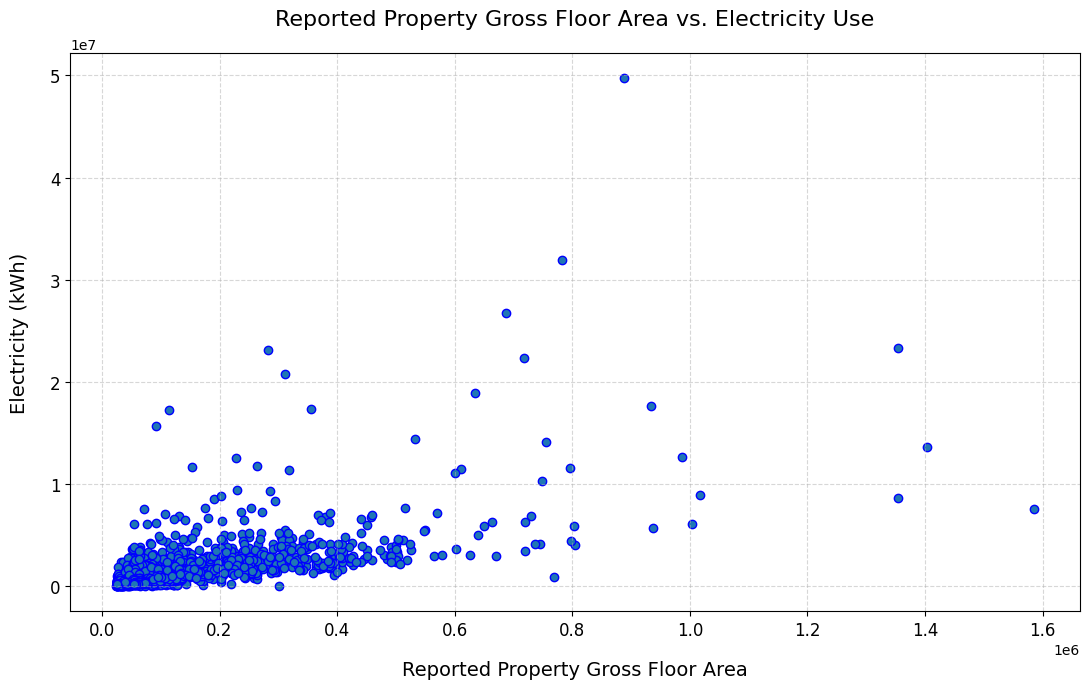

In [62]:
gfa_column = [
    col for col in energy_2023_clean.columns if "Gross Floor Area" in col][0]
elec_column = "Electricity (kWh)"

# drop rows where either Gross Floor Area or Electricity is NaN
# default is to replace with mean or median
scatter_data = energy_2023_clean[[gfa_column, elec_column]].dropna().copy()

# convert to numeric values
for col in [gfa_column, elec_column]:
    scatter_data[col] = scatter_data[
        col].astype(str).str.replace(",", "", regex = True)
    scatter_data[col] = pd.to_numeric(scatter_data[col], errors = "coerce")

scatter_data = scatter_data.dropna()

plt.figure(figsize = (11, 7))
plt.scatter(
    scatter_data[gfa_column],
    scatter_data[elec_column], color = "#1f77b4", edgecolor = "blue")

plt.title(
    "Reported Property Gross Floor Area vs. Electricity Use",
    pad = 20, fontsize = fs_title)
plt.xlabel(gfa_column, labelpad = 15, fontsize = fs_label)
plt.ylabel(elec_column, labelpad = 15, fontsize = fs_label)
plt.xticks(fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

### Graph 6: Zoomed-in Scatterplot of Gross Floor Area vs. Electricity Use

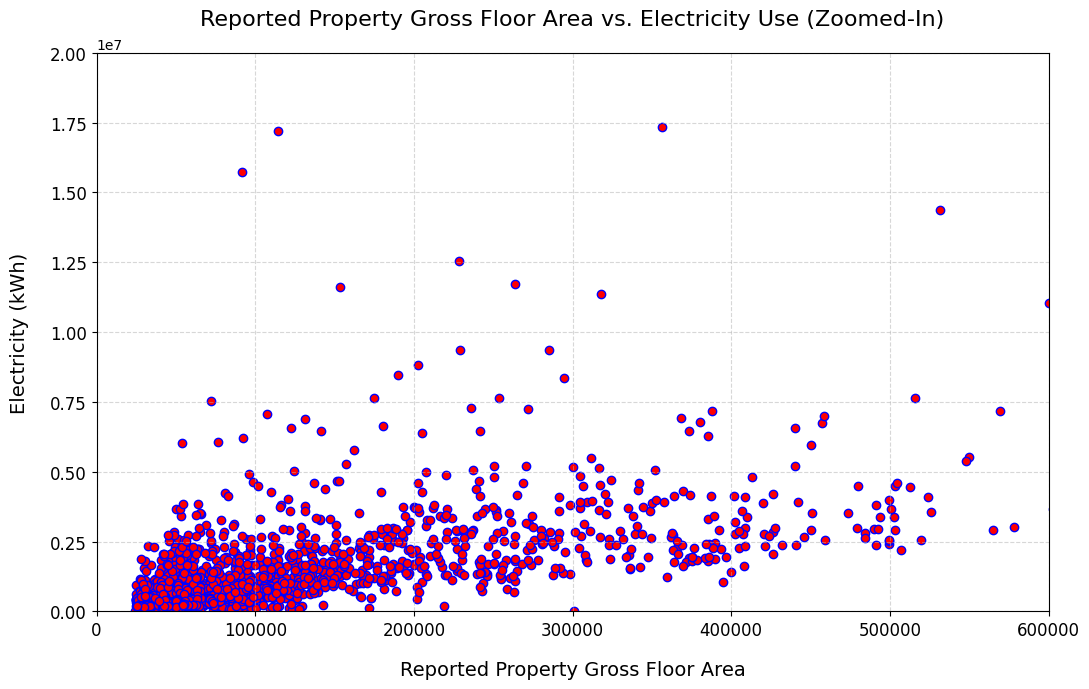

In [65]:
plt.figure(figsize = (11, 7))
plt.scatter(
    scatter_data[gfa_column], scatter_data[elec_column],
    color = "red", edgecolor = "blue")

plt.title(
    "Reported Property Gross Floor Area vs. Electricity Use (Zoomed-In)",
    pad = 20, fontsize = fs_title)
plt.xlabel(gfa_column, labelpad = 15, fontsize = fs_label)
plt.ylabel(elec_column, labelpad = 15, fontsize = fs_label)

# set limits to zoom in on the lower-left portion
plt.xlim(0, 0.6e6)
plt.ylim(0, 2.0e7)

plt.xticks(fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

### Graph 7:  Building Age vs. ENERGY STAR Score

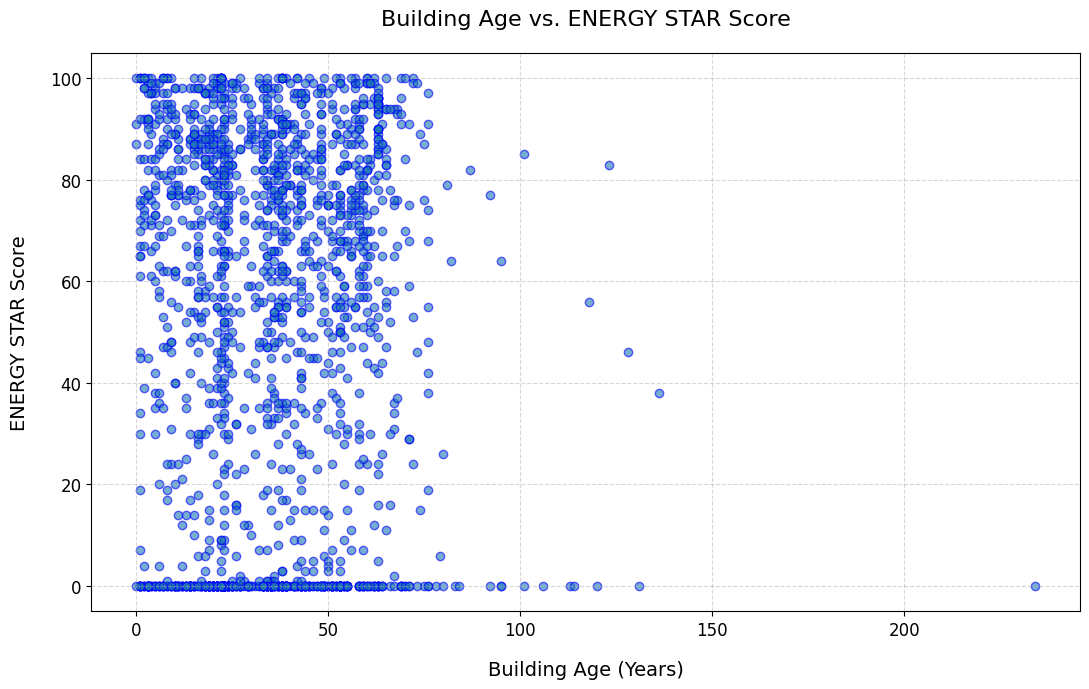

In [66]:
# find correct column names in energy_2023_clean
year_built_col = [
    col for col in energy_2023_clean.columns if "Year Built" in col or "year built" in col.lower()][0]
score_col = [
    col for col in energy_2023_clean.columns if "STAR" in col or "star score" in col.lower()][0]

# create copy and drop rows where year_built_col is NaN
plot_df = energy_2023_clean.dropna(subset = [year_built_col]).copy()

# convert to numeric for subtraction and plotting
plot_df[year_built_col] = pd.to_numeric(plot_df[year_built_col], errors = "coerce")
plot_df[score_col] = pd.to_numeric(plot_df[score_col], errors = "coerce")
plot_df = plot_df.dropna(subset = [year_built_col, score_col])

# calculate building age in 2023
plot_df["building age"] = 2023 - plot_df[year_built_col]

# Building Age vs ENERGY STAR Score
plt.figure(figsize = (11, 7))
plt.scatter(plot_df["building age"], plot_df[score_col], color = "#1f77b4", edgecolor = "blue", alpha = 0.6)

plt.title("Building Age vs. ENERGY STAR Score", pad = 20, fontsize = fs_title)
plt.xlabel("Building Age (Years)", labelpad = 15, fontsize = fs_label)
plt.ylabel(score_col, labelpad = 15, fontsize = fs_label)
plt.xticks(fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

### Graph 8: Scatterplot of ENERGY STAR Score vs. Total GHG Emissions

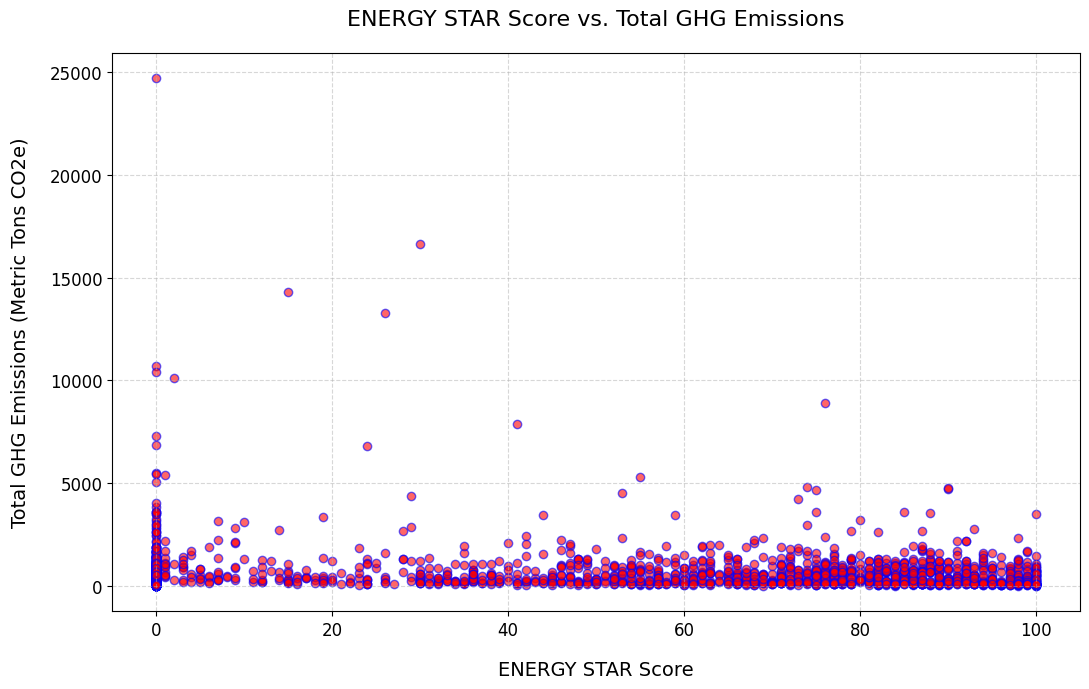

In [79]:
# drop rows where either ENERGY STAR Score or Total GHG Emissions is NaN
scatter_data_ghg = energy_2023_clean[[score_col, ghg_column]].dropna().copy()

# convert to numeric
for col in [score_col, ghg_column]:
    scatter_data_ghg[col] = scatter_data_ghg[
        col].astype(str).str.replace(",", "", regex = True)
    scatter_data_ghg[col] = pd.to_numeric(scatter_data_ghg[col],
                                          errors = "coerce")

scatter_data_ghg = scatter_data_ghg.dropna()

plt.figure(figsize = (11, 7))
plt.scatter(scatter_data_ghg[score_col], scatter_data_ghg[
    ghg_column], color = "red", edgecolor = "blue", alpha = 0.6)

plt.title(
    "ENERGY STAR Score vs. Total GHG Emissions", pad = 20, fontsize = fs_title)
plt.xlabel(score_col, labelpad = 15, fontsize = fs_label)
plt.ylabel(ghg_column, labelpad = 15, fontsize = fs_label)
plt.xticks(fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

### Graph 9: Scatterplot of Building Age vs. Total GHG Emissions

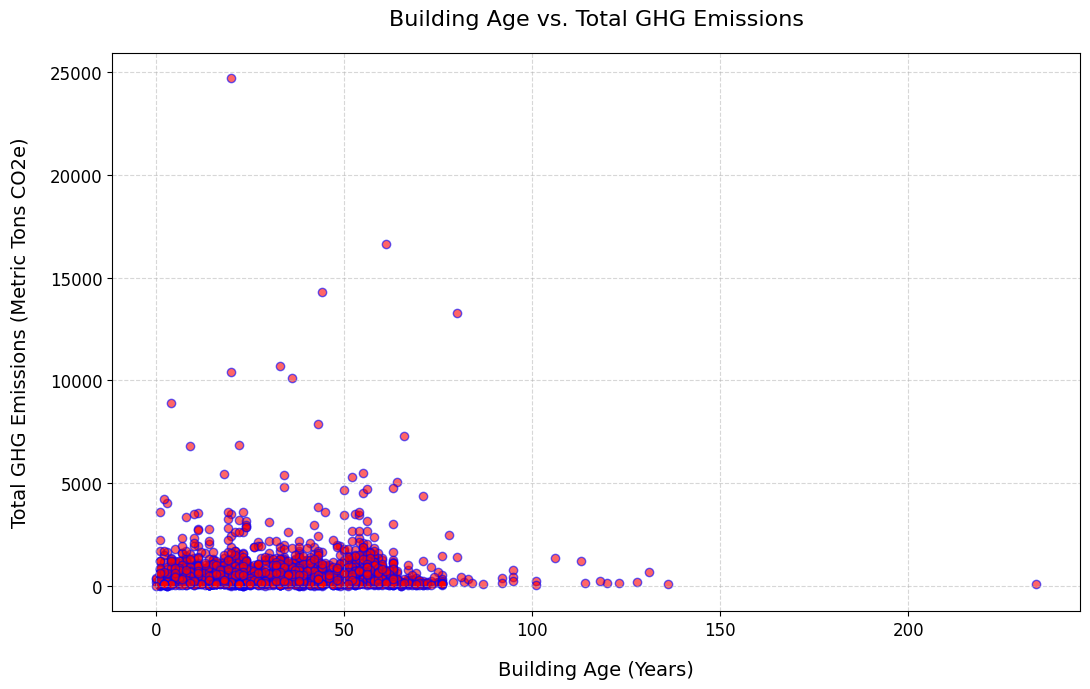

In [68]:
# drop rows where either year built (for building age) or Total GHG Emissions NaN
plot_df_ghg = energy_2023_clean.dropna(
    subset = [year_built_col, ghg_column]).copy()

# convert to numeric
plot_df_ghg[year_built_col] = pd.to_numeric(plot_df_ghg[year_built_col],
                                            errors = "coerce")
plot_df_ghg[ghg_column] = pd.to_numeric(
    plot_df_ghg[ghg_column].astype(str).str.replace(",", "", regex = True),
    errors = "coerce")
plot_df_ghg = plot_df_ghg.dropna(subset = [year_built_col, ghg_column])

# create "building age"
plot_df_ghg["building age"] = 2023 - plot_df_ghg[year_built_col]

plt.figure(figsize = (11, 7))
plt.scatter(
    plot_df_ghg["building age"], plot_df_ghg[ghg_column],
    color = "red", edgecolor = "blue", alpha = 0.6)

plt.title("Building Age vs. Total GHG Emissions", pad = 20, fontsize = fs_title)
plt.xlabel("Building Age (Years)", labelpad = 15, fontsize = fs_label)
plt.ylabel(ghg_column, labelpad = 15, fontsize = fs_label)
plt.xticks(fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

### Graph 9.1: Zoomed-In Scatterplot of Building Age vs. Total GHG Emissions

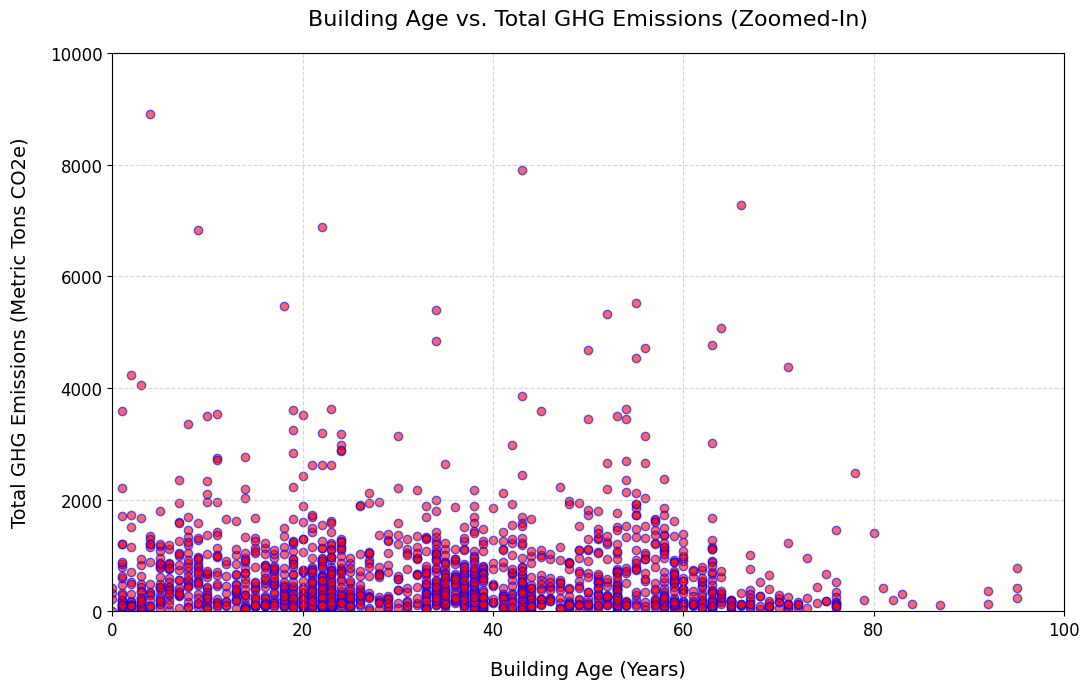

In [80]:
plt.figure(figsize = (11, 7))
plt.scatter(
    plot_df_ghg["building age"], plot_df_ghg[ghg_column],
    color = "red", edgecolor = "blue", alpha = 0.6)

plt.title(
    "Building Age vs. Total GHG Emissions (Zoomed-In)",
    pad = 20, fontsize = fs_title)
plt.xlabel("Building Age (Years)", labelpad = 15, fontsize = fs_label)
plt.ylabel(ghg_column, labelpad = 15, fontsize = fs_label)

# zoom limits
plt.xlim(0, 100)
plt.ylim(0, 10000)

plt.xticks(fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

### Graph 10: Histogram and Density Plot of Energy Use Intensity

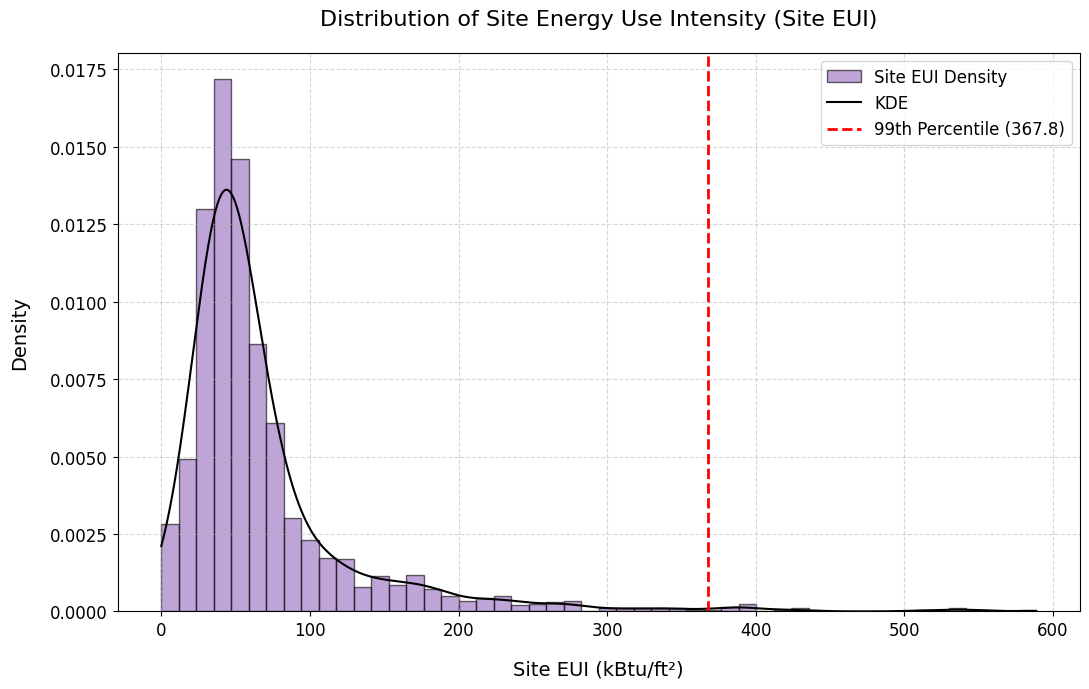

In [75]:
eui_col = "Site EUI"

# drop NaN values and clean strings
eui_data = energy_2023_clean[eui_col].dropna().copy()
eui_data = pd.to_numeric(
    eui_data.astype(str).str.replace(",", "", regex = True),
    errors = "coerce").dropna()

plt.figure(figsize = (11, 7))

plt.hist(
    eui_data, bins = 50, density = True, color = "#9467bd",
    edgecolor = "black", alpha = 0.6, label = "Site EUI Density")

# re-calculate, plot KDE separately
from scipy.stats import gaussian_kde
import numpy as np
kde = gaussian_kde(eui_data)
x_vals = np.linspace(eui_data.min(), eui_data.max(), 1000)
plt.plot(x_vals, kde(x_vals), color = "black", linewidth = 1.5, label = "KDE")

# highlight outliers
threshold = eui_data.quantile(0.99)
plt.axvline(
    threshold, color = "red", linestyle = "--", linewidth = 2,
    label = f"99th Percentile ({threshold:.1f})")

plt.title(
    "Distribution of Site Energy Use Intensity (Site EUI)",
    pad = 20, fontsize = fs_title)
plt.xlabel("Site EUI (kBtu/ft²)", labelpad = 15, fontsize = fs_label)
plt.ylabel("Density", labelpad = 15, fontsize = fs_label)
plt.xticks(fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.legend(fontsize = fs_ticks)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

### Graph 11: Scatterplot of Gross Floor Area vs. Electricity Use Color-Coded by Property Type

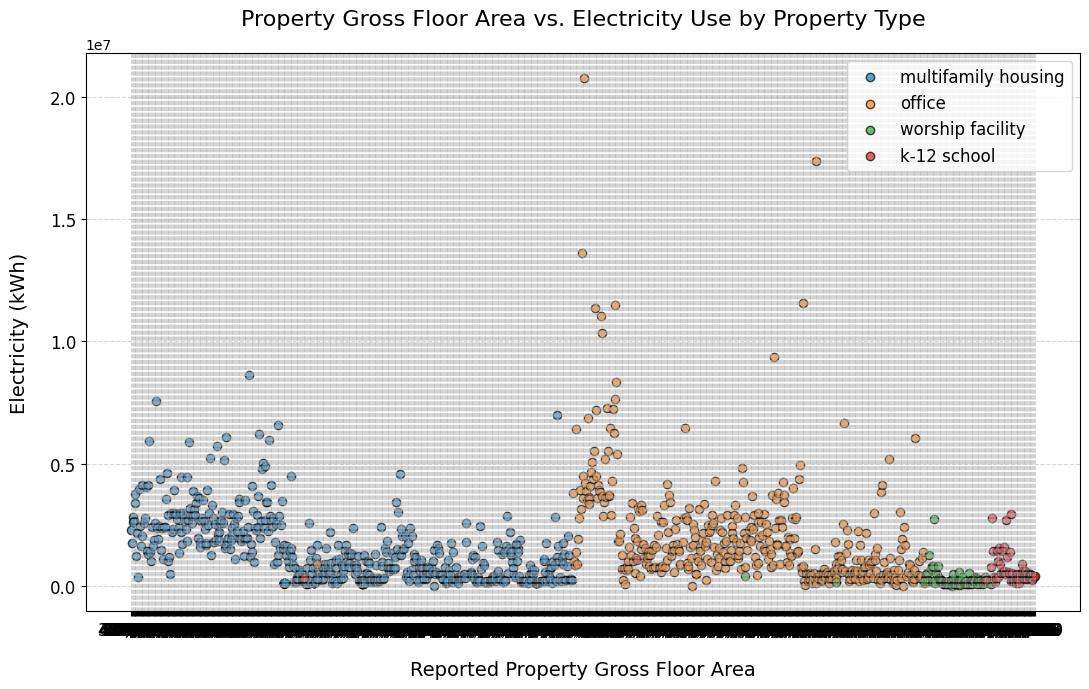

In [74]:
plt.figure(figsize = (11, 7))

# loop through each property type and plot with its corresponding color
for prop, color in zip(target_properties, colors_sub):
    sub_df = filtered_df[filtered_df["Primary Property Type EPA Calculated"] == prop]
    plt.scatter(
        sub_df[gfa_column],
        sub_df[electricity_column],
        color = color,
        edgecolor = "black",
        alpha = 0.7,
        label = prop
    )

plt.title(
    "Property Gross Floor Area vs. Electricity Use by Property Type",
    pad = 20, fontsize = fs_title)
plt.xlabel(gfa_column, labelpad = 15, fontsize = fs_label)
plt.ylabel(electricity_column, labelpad = 15, fontsize = fs_label)
plt.xticks(fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.legend(fontsize = fs_ticks)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()

### Graph 12: Boxplots of ENERGY STAR Ratings by Property Type

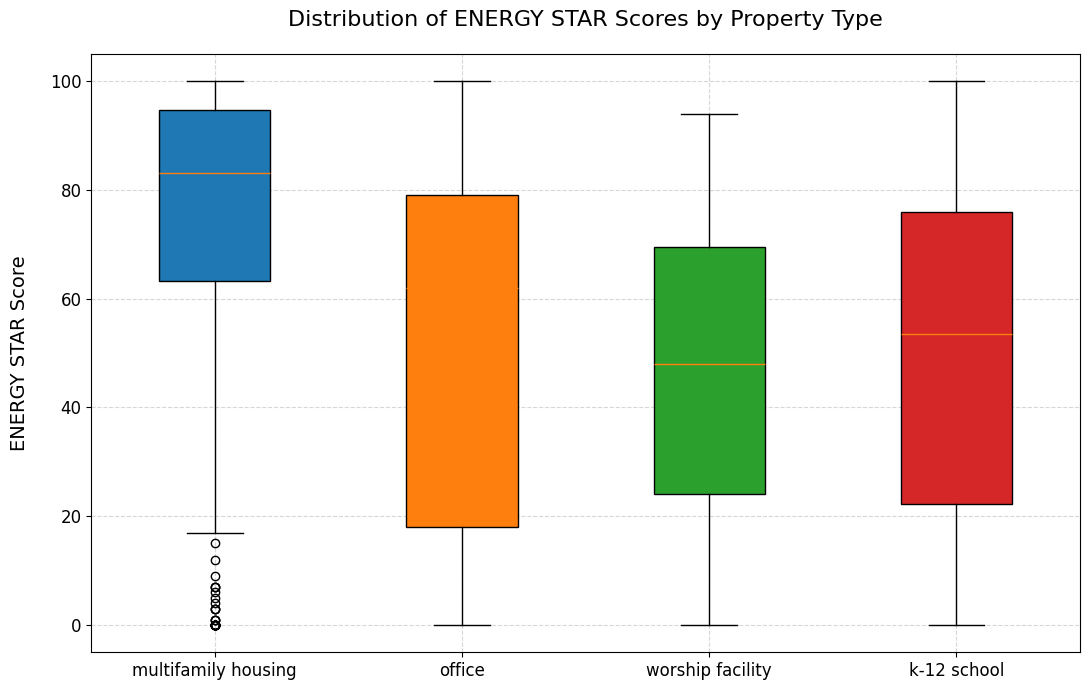

In [81]:
plt.figure(figsize = (11, 7))

# filter out NaN vals
score_data = [
    filtered_df[
        (filtered_df["Primary Property Type EPA Calculated"] == prop) &
        (filtered_df[score_col].notna())
    ][score_col]
    for prop in target_properties
]

bp_star = plt.boxplot(
    score_data,
    tick_labels = target_properties,
    patch_artist = True
)

# apply colors to each box
for patch, color in zip(bp_star["boxes"], colors_sub):
    patch.set_facecolor(color)

plt.title("Distribution of ENERGY STAR Scores by Property Type", pad = 20, fontsize = fs_title)
plt.ylabel("ENERGY STAR Score", labelpad = 15, fontsize = fs_label)
plt.xticks(rotation = 0, fontsize = fs_ticks)
plt.yticks(fontsize = fs_ticks)
plt.grid(True, linestyle = "--", alpha = 0.5)
plt.tight_layout()
plt.show()